In [1]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/realtor-data.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (2226382, 12)


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN


In [2]:
# Загальна інформація про датасет
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2226382 entries, 0 to 2226381
Data columns (total 12 columns):
 #   Column          Dtype  
---  ------          -----  
 0   brokered_by     float64
 1   status          object 
 2   price           float64
 3   bed             float64
 4   bath            float64
 5   acre_lot        float64
 6   street          float64
 7   city            object 
 8   state           object 
 9   zip_code        float64
 10  house_size      float64
 11  prev_sold_date  object 
dtypes: float64(8), object(4)
memory usage: 203.8+ MB


In [3]:
# Аналіз пропущених значень
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().sum() / len(df) * 100).round(2)
})

missing.sort_values("missing_percent", ascending=False)

,missing_count,missing_percent
prev_sold_date,734297,32.98
house_size,568484,25.53
bath,511771,22.99
bed,481317,21.62
acre_lot,325589,14.62
street,10866,0.49
brokered_by,4533,0.20
price,1541,0.07
city,1407,0.06
zip_code,299,0.01


In [4]:
# Перевірка повністю дубльованих рядків
duplicate_count = df.duplicated().sum()
duplicate_percent = duplicate_count / len(df) * 100

print(f"Кількість дублікатів: {duplicate_count:,}")
print(f"Відсоток дублікатів: {duplicate_percent:.2f}%")

Кількість дублікатів: 0
Відсоток дублікатів: 0.00%


In [5]:
# Описова статистика числових ознак
df.describe().T

,count,mean,std,min,25%,50%,75%,max
brokered_by,2221849.0,5.293989e+04,3.064275e+04,0.0,23861.00,52884.00,79183.00,1.101420e+05
price,2224841.0,5.241955e+05,2.138893e+06,0.0,165000.00,325000.00,550000.00,2.147484e+09
bed,1745065.0,3.275841e+00,1.567274e+00,1.0,3.00,3.00,4.00,4.730000e+02
bath,1714611.0,2.496440e+00,1.652573e+00,1.0,2.00,2.00,3.00,8.300000e+02
acre_lot,1900793.0,1.522303e+01,7.628238e+02,0.0,0.15,0.26,0.98,1.000000e+05
street,2215516.0,1.012325e+06,5.837635e+05,0.0,506312.75,1012765.50,1521173.25,2.001357e+06
zip_code,2226083.0,5.218668e+04,2.895408e+04,0.0,29617.00,48382.00,78070.00,9.999900e+04
house_size,1657898.0,2.714471e+03,8.081635e+05,4.0,1300.00,1760.00,2413.00,1.040400e+09


In [6]:
# Перцентилі основних числових ознак
columns = ["price", "bed", "bath", "acre_lot", "house_size"]

percentiles = df[columns].quantile([
    0.01,
    0.25,
    0.50,
    0.75,
    0.90,
    0.95,
    0.99,
    0.999
])

percentiles

,price,bed,bath,acre_lot,house_size
0.010,10000.0,1.0,1.0,0.0200,598.000
0.250,165000.0,3.0,2.0,0.1500,1300.000
0.500,325000.0,3.0,2.0,0.2600,1760.000
0.750,550000.0,4.0,3.0,0.9800,2413.000
0.900,949000.0,4.0,4.0,5.0000,3279.000
0.950,1495000.0,5.0,4.0,14.0200,4008.000
0.990,3899000.0,7.0,6.0,98.0000,6439.030
0.999,14500000.0,14.0,12.0,896.6976,14512.927


In [7]:
# Аналіз категоріальних ознак
categorical_columns = ["status", "city", "state"]

for column in categorical_columns:
    print(f"\n      {column}")
    print(f"Унікальних значень: {df[column].nunique()}")
    print(df[column].value_counts().head(15))


      status
Унікальних значень: 3
status
for_sale          1389306
sold               812009
ready_to_build      25067
Name: count, dtype: int64

      city
Унікальних значень: 20098
city
Houston          23862
Chicago          18238
New York City    12634
Jacksonville     11743
Philadelphia     10449
Miami             9737
Los Angeles       8984
Tucson            8943
Dallas            8569
Richmond          8360
Phoenix           8290
Washington        8220
San Antonio       7342
Atlanta           7267
Orlando           7187
Name: count, dtype: int64

      state
Унікальних значень: 55
state
Florida           249432
California        227215
Texas             208335
New York          103159
North Carolina     85745
Illinois           85280
Georgia            80977
Pennsylvania       78373
Arizona            72825
Virginia           68763
Washington         62461
Ohio               59207
New Jersey         48199
Maryland           46052
Missouri           45145
Name: count, dtype: in

In [8]:
# Аналіз дати попереднього продажу
df["prev_sold_date"].head(10)

0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
5    NaN
6    NaN
7    NaN
8    NaN
9    NaN
Name: prev_sold_date, dtype: object

In [9]:
# Перевіряємо діапазон дат без зміни оригінального DataFrame
prev_sold_date = pd.to_datetime(
    df["prev_sold_date"],
    errors="coerce"
)

print("Найраніша дата:", prev_sold_date.min())
print("Найпізніша дата:", prev_sold_date.max())
print("Не вдалося перетворити:", 
      prev_sold_date.isna().sum() - df["prev_sold_date"].isna().sum())

Найраніша дата: 1901-01-01 00:00:00
Найпізніша дата: 2026-04-08 00:00:00
Не вдалося перетворити: 1


In [10]:
# Знаходимо значення, яке не вдалося перетворити на дату
invalid_date_mask = (
    df["prev_sold_date"].notna()
    & prev_sold_date.isna()
)

df.loc[invalid_date_mask, ["prev_sold_date", "price", "city", "state"]]

,prev_sold_date,price,city,state
1474557,3019-04-02,325000.0,Long Beach,New York


In [11]:
# Перевіряємо кількість дуже старих та майбутніх дат
print("До 1950 року:", (prev_sold_date.dt.year < 1950).sum())
print("Після 2025 року:", (prev_sold_date.dt.year > 2025).sum())

До 1950 року: 13
Після 2025 року: 1


In [12]:
# Переглядаємо дуже старі та майбутні дати
extreme_dates_mask = (
    (prev_sold_date.dt.year < 1950)
    | (prev_sold_date.dt.year > 2025)
)

df.loc[
    extreme_dates_mask,
    ["prev_sold_date", "price", "bed", "bath",
     "house_size", "city", "state"]
].sort_values("prev_sold_date")

,prev_sold_date,price,bed,bath,house_size,city,state
8066,1901-01-01,339000.0,3.0,2.0,1922.0,Lee,Massachusetts
688843,1904-03-18,249900.0,3.0,2.0,1860.0,Caledonia,Ohio
993348,1905-07-17,405000.0,3.0,3.0,2617.0,Norman,Oklahoma
1141177,1906-10-29,345000.0,2.0,3.0,1275.0,Westminster,Colorado
161578,1909-01-19,85900.0,3.0,1.0,1162.0,California,Pennsylvania
541598,1909-03-01,450000.0,3.0,3.0,1596.0,Fort Myers,Florida
8063,1910-01-29,269000.0,4.0,2.0,2260.0,Lee,Massachusetts
353258,1926-11-30,599999.0,NaN,NaN,NaN,Nichols,South Carolina
180891,1928-03-27,6885000.0,NaN,NaN,NaN,Mount Joy,Pennsylvania
174958,1935-08-01,135900.0,3.0,1.0,1056.0,Tionesta,Pennsylvania


In [13]:
# Створюємо копію сирих даних для очищення
df_clean = df.copy()

print("Рядків до очищення:", len(df_clean))

Рядків до очищення: 2226382


In [14]:
# Видаляємо записи без цільової змінної price
df_clean = df_clean.dropna(subset=["price"])

print("Рядків після видалення пропусків price:", len(df_clean))
print("Видалено:", len(df) - len(df_clean))

Рядків після видалення пропусків price: 2224841
Видалено: 1541


In [15]:
# Перевірка дуже низьких значень price
print("price = 0:", (df_clean["price"] == 0).sum())
print("price < 1 000:", (df_clean["price"] < 1_000).sum())
print("price < 10 000:", (df_clean["price"] < 10_000).sum())
print("price < 50 000:", (df_clean["price"] < 50_000).sum())

price = 0: 280
price < 1 000: 1226
price < 10 000: 19271
price < 50 000: 188976


In [16]:
# Перевірка дуже високих значень price
print("price > 5 млн:", (df_clean["price"] > 5_000_000).sum())
print("price > 10 млн:", (df_clean["price"] > 10_000_000).sum())
print("price > 50 млн:", (df_clean["price"] > 50_000_000).sum())
print("price > 100 млн:", (df_clean["price"] > 100_000_000).sum())

price > 5 млн: 13655
price > 10 млн: 3996
price > 50 млн: 130
price > 100 млн: 24


In [17]:
# 10 об'єктів з найнижчими цінами
df_clean[
    ["price", "bed", "bath", "acre_lot",
     "house_size", "city", "state", "status"]
].sort_values("price").head(10)

,price,bed,bath,acre_lot,house_size,city,state,status
1176582,0.0,3.0,NaN,NaN,2065.0,Nampa,Idaho,ready_to_build
1176579,0.0,4.0,NaN,NaN,3259.0,Nampa,Idaho,ready_to_build
1176593,0.0,3.0,NaN,NaN,2636.0,Nampa,Idaho,ready_to_build
1176592,0.0,3.0,NaN,NaN,2483.0,Nampa,Idaho,ready_to_build
1176591,0.0,3.0,NaN,NaN,2007.0,Nampa,Idaho,ready_to_build
1176590,0.0,3.0,NaN,NaN,2290.0,Nampa,Idaho,ready_to_build
1176564,0.0,4.0,NaN,NaN,3435.0,Nampa,Idaho,ready_to_build
1176578,0.0,4.0,NaN,NaN,3277.0,Nampa,Idaho,ready_to_build
1176577,0.0,4.0,NaN,NaN,2679.0,Nampa,Idaho,ready_to_build
1176567,0.0,4.0,NaN,NaN,3064.0,Nampa,Idaho,ready_to_build


In [18]:
# 10 об'єктів з найвищими цінами
df_clean[
    ["price", "bed", "bath", "acre_lot",
     "house_size", "city", "state", "status"]
].sort_values("price", ascending=False).head(10)

,price,bed,bath,acre_lot,house_size,city,state,status
221994,2.147484e+09,2.0,2.0,0.12,885.0,International,California,for_sale
941987,1.000000e+09,NaN,NaN,101.00,NaN,Eureka,Kansas,for_sale
72903,8.750000e+08,9.0,2.0,NaN,2440.0,Bronx,New York,for_sale
1288464,5.150000e+08,2.0,2.0,2.59,1048.0,San Diego,California,for_sale
2054444,2.950000e+08,21.0,49.0,3.83,NaN,Los Angeles,California,sold
375790,2.815000e+08,3.0,3.0,0.03,NaN,Atlanta,Georgia,for_sale
1258956,2.500000e+08,19.0,33.0,36.73,NaN,Beverly Hills,California,for_sale
1051157,2.125000e+08,NaN,NaN,50.00,NaN,Kosse,Texas,for_sale
105334,1.690000e+08,6.0,9.0,0.79,8255.0,New York City,New York,for_sale
1258584,1.650000e+08,14.0,27.0,4.60,56500.0,Los Angeles,California,for_sale


In [19]:
# Видаляємо записи з нульовою або від'ємною ціною
rows_before = len(df_clean)

df_clean = df_clean[df_clean["price"] > 0].copy()

print("Було рядків:", rows_before)
print("Стало рядків:", len(df_clean))
print("Видалено:", rows_before - len(df_clean))

Було рядків: 2224841
Стало рядків: 2224561
Видалено: 280


In [20]:
# Порівняння об'єктів за статусом
status_stats = df_clean.groupby("status").agg(
    count=("price", "size"),
    median_price=("price", "median"),
    mean_price=("price", "mean"),
    median_bed=("bed", "median"),
    median_bath=("bath", "median"),
    median_house_size=("house_size", "median")
)

status_stats

,count,median_price,mean_price,median_bed,median_bath,median_house_size
status,,,,,,
for_sale,1388345,305000.0,547868.064877,3.0,2.0,1805.0
ready_to_build,24452,455990.0,514819.046704,4.0,NaN,2300.0
sold,811764,344900.0,484172.049355,3.0,2.0,1680.0


In [21]:
# Залишаємо активні оголошення про продаж
rows_before = len(df_clean)

df_clean = df_clean[
    df_clean["status"] == "for_sale"
].copy()

print("Було рядків:", rows_before)
print("Стало рядків:", len(df_clean))
print("Виключено інших статусів:", rows_before - len(df_clean))

Було рядків: 2224561
Стало рядків: 1388345
Виключено інших статусів: 836216


In [22]:
# Пропуски після відбору оголошень for_sale
missing_clean = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (
        df_clean.isna().sum() / len(df_clean) * 100
    ).round(2)
})

missing_clean.sort_values(
    "missing_percent",
    ascending=False
)

,missing_count,missing_percent
prev_sold_date,708527,51.03
house_size,464231,33.44
bed,410941,29.60
bath,408402,29.42
acre_lot,192800,13.89
street,7698,0.55
brokered_by,1483,0.11
city,1306,0.09
zip_code,286,0.02
status,0,0.00


In [23]:
# Перевіряємо комбінації пропусків у ключових характеристиках
key_features = ["bed", "bath", "house_size", "acre_lot"]

missing_patterns = (
    df_clean[key_features]
    .isna()
    .value_counts()
    .reset_index(name="count")
)

missing_patterns["percent"] = (
    missing_patterns["count"] / len(df_clean) * 100
).round(2)

missing_patterns.head(15)

,bed,bath,house_size,acre_lot,count,percent
0,False,False,False,False,750932,54.09
1,True,True,True,False,386968,27.87
2,False,False,False,True,157626,11.35
3,False,False,True,False,45565,3.28
4,False,False,True,True,18853,1.36
5,True,True,True,True,10713,0.77
6,True,True,False,False,5530,0.40
7,False,True,False,False,3637,0.26
8,True,False,False,True,3277,0.24
9,True,False,False,False,2074,0.15


In [24]:
# Об'єкти без bed, bath і house_size,
# але з відомою площею земельної ділянки
land_like_mask = (
    df_clean["bed"].isna()
    & df_clean["bath"].isna()
    & df_clean["house_size"].isna()
    & df_clean["acre_lot"].notna()
)

land_like = df_clean[land_like_mask]

print("Кількість таких об'єктів:", len(land_like))

Кількість таких об'єктів: 386968


In [25]:
land_like[
    [
        "price",
        "acre_lot",
        "street",
        "city",
        "state",
        "zip_code",
        "status"
    ]
].head(20)

,price,acre_lot,street,city,state,zip_code,status
43,380000.0,18.45,1855421.0,Hatillo,Puerto Rico,659.0,for_sale
59,35000.0,0.88,1234597.0,Aguada,Puerto Rico,602.0,for_sale
60,58000.0,0.21,1966337.0,Aguada,Puerto Rico,602.0,for_sale
61,85000.0,21.08,1188097.0,Aguada,Puerto Rico,602.0,for_sale
62,47000.0,0.57,1841588.0,Aguada,Puerto Rico,602.0,for_sale
65,50000.0,0.65,1946326.0,Aguada,Puerto Rico,602.0,for_sale
67,39500.0,0.24,1902841.0,Aguada,Puerto Rico,602.0,for_sale
68,249500.0,33.35,1032552.0,Aguada,Puerto Rico,602.0,for_sale
71,649000.0,2.64,1946165.0,Aguada,Puerto Rico,602.0,for_sale
73,150000.0,1.46,1902798.0,Aguada,Puerto Rico,602.0,for_sale


In [26]:
land_like[
    ["price", "acre_lot"]
].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]
).T

,count,mean,std,min,25%,50%,75%,90%,99%,max
price,386968.0,315728.232763,2.045192e+06,1.0,35000.00,80000.0,230000.0,610354.5,3.800000e+06,1.000000e+09
acre_lot,386968.0,22.588035,6.105121e+02,0.0,0.39,1.2,5.3,28.0,2.421728e+02,1.000000e+05


In [27]:
# Залишаємо об'єкти з відомими базовими характеристиками житла
rows_before = len(df_clean)

df_clean = df_clean.dropna(
    subset=["bed", "bath", "house_size"]
).copy()

print("Було рядків:", rows_before)
print("Стало рядків:", len(df_clean))
print("Виключено:", rows_before - len(df_clean))
print(
    "Збережено:",
    round(len(df_clean) / rows_before * 100, 2),
    "%"
)

Було рядків: 1388345
Стало рядків: 908558
Виключено: 479787
Збережено: 65.44 %


In [28]:
# Перевіряємо пропуски після відбору житлових об'єктів
missing_after_filter = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (
        df_clean.isna().sum() / len(df_clean) * 100
    ).round(2)
})

missing_after_filter.sort_values(
    "missing_percent",
    ascending=False
)

,missing_count,missing_percent
prev_sold_date,355032,39.08
acre_lot,157626,17.35
street,3850,0.42
brokered_by,855,0.09
city,330,0.04
zip_code,95,0.01
status,0,0.00
price,0,0.00
bed,0,0.00
bath,0,0.00


In [29]:
# Кількість унікальних значень у потенційних категоріальних/ID ознаках
columns_to_check = [
    "state",
    "city",
    "zip_code",
    "street",
    "brokered_by"
]

for column in columns_to_check:
    unique_count = df_clean[column].nunique()
    unique_percent = unique_count / len(df_clean) * 100

    print(
        f"{column:12} | "
        f"unique: {unique_count:,} | "
        f"{unique_percent:.2f}%"
    )

state        | unique: 54 | 0.01%
city         | unique: 16,576 | 1.82%
zip_code     | unique: 27,145 | 2.99%
street       | unique: 894,686 | 98.47%
brokered_by  | unique: 84,273 | 9.28%


In [30]:
# Перевіряємо формат ZIP-кодів
print(df_clean["zip_code"].head(20))

print("\nМінімальний ZIP:", df_clean["zip_code"].min())
print("Максимальний ZIP:", df_clean["zip_code"].max())

print(
    "ZIP-кодів з дробовою частиною:",
    ((df_clean["zip_code"].dropna() % 1) != 0).sum()
)

0     601.0
1     601.0
2     795.0
3     731.0
5     612.0
6     639.0
7     731.0
8     730.0
9     670.0
10    662.0
11    795.0
12    669.0
13    641.0
14    731.0
15    698.0
16    680.0
17    728.0
18    685.0
19    610.0
20    698.0
Name: zip_code, dtype: float64

Мінімальний ZIP: 0.0
Максимальний ZIP: 99999.0
ZIP-кодів з дробовою частиною: 0


In [31]:
# Перетворюємо дату попереднього продажу
prev_sold = pd.to_datetime(
    df_clean["prev_sold_date"],
    errors="coerce"
)

# Створюємо тимчасовий DataFrame для аналізу
date_analysis = pd.DataFrame({
    "prev_sold_year": prev_sold.dt.year,
    "price": df_clean["price"]
})

date_analysis.head()

,prev_sold_year,price
0,NaN,105000.0
1,NaN,80000.0
2,NaN,67000.0
3,NaN,145000.0
5,NaN,179000.0


In [32]:
# Статистика року попереднього продажу
date_analysis["prev_sold_year"].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
)

count    553526.000000
mean       2012.015170
std           9.519931
min        1901.000000
1%         1981.000000
25%        2006.000000
50%        2015.000000
75%        2019.000000
99%        2022.000000
max        2026.000000
Name: prev_sold_year, dtype: float64

In [33]:
# Найчастіші роки попереднього продажу
date_analysis["prev_sold_year"].value_counts().head(15)

prev_sold_year
2021.0    54504
2019.0    41391
2022.0    39343
2018.0    38017
2020.0    36892
2017.0    32888
2016.0    28945
2015.0    24595
2014.0    20183
2013.0    17892
2005.0    16838
2006.0    16217
2007.0    14531
2012.0    13938
2004.0    13838
Name: count, dtype: int64

In [34]:
# Ознаки першої версії моделі
FEATURES = [
    "bed",
    "bath",
    "house_size",
    "acre_lot",
    "state",
    "city",
    "zip_code"
]

TARGET = "price"

X = df_clean[FEATURES].copy()
y = df_clean[TARGET].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (908558, 7)
y shape: (908558,)


,bed,bath,house_size,acre_lot,state,city,zip_code
0,3.0,2.0,920.0,0.12,Puerto Rico,Adjuntas,601.0
1,4.0,2.0,1527.0,0.08,Puerto Rico,Adjuntas,601.0
2,2.0,1.0,748.0,0.15,Puerto Rico,Juana Diaz,795.0
3,4.0,2.0,1800.0,0.10,Puerto Rico,Ponce,731.0
5,4.0,3.0,2520.0,0.46,Puerto Rico,San Sebastian,612.0


In [35]:
print("Типи ознак:")
print(X.dtypes)

print("\nПропуски:")
print(X.isna().sum())

Типи ознак:
bed           float64
bath          float64
house_size    float64
acre_lot      float64
state          object
city           object
zip_code      float64
dtype: object

Пропуски:
bed                0
bath               0
house_size         0
acre_lot      157626
state              0
city             330
zip_code          95
dtype: int64


In [36]:
from sklearn.model_selection import train_test_split

In [37]:
# Розділяємо дані на train та test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (726846, 7)
Test: (181712, 7)


In [38]:
numeric_features = [
    "bed",
    "bath",
    "house_size",
    "acre_lot"
]

In [39]:
location_features = [
    "state",
    "city",
    "zip_code"
]

In [40]:
# Перевіряємо категорії, які є в test, але відсутні в train
for column in ["state", "city", "zip_code"]:
    train_values = set(X_train[column].dropna())
    test_values = set(X_test[column].dropna())

    unseen = test_values - train_values

    print(f"{column}:")
    print(f"  категорій у train: {len(train_values):,}")
    print(f"  категорій у test: {len(test_values):,}")
    print(f"  нових категорій у test: {len(unseen):,}")

state:
  категорій у train: 54
  категорій у test: 54
  нових категорій у test: 0
city:
  категорій у train: 16,009
  категорій у test: 11,878
  нових категорій у test: 567
zip_code:
  категорій у train: 26,344
  категорій у test: 20,335
  нових категорій у test: 801


In [41]:
from category_encoders import TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [42]:
numeric_features = [
    "bed",
    "bath",
    "house_size",
    "acre_lot"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

In [43]:
state_features = ["state"]

state_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

In [44]:
X_train = X_train.copy()
X_test = X_test.copy()

# ZIP-код: перетворюємо у числовий формат,
# а потім у категоріальний рядковий формат
X_train["zip_code"] = (
    pd.to_numeric(X_train["zip_code"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .fillna("Unknown")
)

X_test["zip_code"] = (
    pd.to_numeric(X_test["zip_code"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .fillna("Unknown")
)

In [45]:
high_cardinality_features = [
    "city",
    "zip_code"
]

high_cardinality_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", TargetEncoder(
        handle_unknown="value",
        handle_missing="value"
    ))
])

In [46]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "state",
            state_pipeline,
            state_features
        ),
        (
            "high_cardinality",
            high_cardinality_pipeline,
            high_cardinality_features
        )
    ],
    remainder="drop"
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('state', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_nam

In [47]:
from sklearn.ensemble import RandomForestRegressor

In [48]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [49]:
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", rf_model)
])

model_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('state', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tran

In [50]:
X_train_small = X_train.iloc[:10_000].copy()
y_train_small = y_train.iloc[:10_000].copy()

print("Test training sample:", X_train_small.shape)

Test training sample: (10000, 7)


In [51]:
from sklearn.base import clone

test_pipeline = clone(model_pipeline)

In [52]:
test_pipeline.fit(
    X_train_small,
    y_train_small
)

print("Pipeline успішно навчено на тестовій вибірці.")

Pipeline успішно навчено на тестовій вибірці.


In [53]:
sample_test = X_test.iloc[:5].copy()
sample_actual = y_test.iloc[:5].copy()

sample_predictions = test_pipeline.predict(sample_test)

prediction_check = pd.DataFrame({
    "actual_price": sample_actual.values,
    "predicted_price": sample_predictions
})

prediction_check

,actual_price,predicted_price
0,920000.0,1071241.12
1,250000.0,419147.46
2,402000.0,534205.28
3,1539000.0,653829.24
4,880000.0,1060079.25


In [54]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline: для всіх об'єктів прогнозуємо медіанну ціну train
baseline_value = y_train.median()

baseline_predictions = np.full(
    len(y_test),
    baseline_value
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print(f"Baseline median price: ${baseline_value:,.2f}")
print(f"Baseline MAE:          ${baseline_mae:,.2f}")
print(f"Baseline RMSE:         ${baseline_rmse:,.2f}")
print(f"Baseline R²:           {baseline_r2:.4f}")

Baseline median price: $380,000.00
Baseline MAE:          $404,615.90
Baseline RMSE:         $1,461,676.36
Baseline R²:           -0.0310


In [55]:
price_stats = df_clean["price"].describe(
    percentiles=[
        0.90,
        0.95,
        0.97,
        0.98,
        0.99,
        0.995,
        0.999
    ]
)

price_stats

count    9.085580e+05
mean     6.351426e+05
std      2.886850e+06
min      1.000000e+00
50%      3.800000e+05
90%      1.099900e+06
95%      1.740000e+06
97%      2.450000e+06
98%      3.150000e+06
99%      4.875000e+06
99.5%    7.300000e+06
99.9%    1.800000e+07
max      2.147484e+09
Name: price, dtype: float64

In [56]:
price_thresholds = [
    1_000_000,
    2_000_000,
    5_000_000,
    10_000_000,
    20_000_000,
    50_000_000,
    100_000_000
]

for threshold in price_thresholds:
    count = (df_clean["price"] > threshold).sum()
    percent = count / len(df_clean) * 100

    print(
        f"> ${threshold:>11,.0f}: "
        f"{count:>7,} ({percent:.4f}%)"
    )

> $  1,000,000:  96,753 (10.6491%)
> $  2,000,000:  34,587 (3.8068%)
> $  5,000,000:   8,199 (0.9024%)
> $ 10,000,000:   2,546 (0.2802%)
> $ 20,000,000:     686 (0.0755%)
> $ 50,000,000:      80 (0.0088%)
> $100,000,000:      11 (0.0012%)


In [57]:
extreme_prices = df_clean[
    df_clean["price"] > 50_000_000
][
    [
        "price",
        "bed",
        "bath",
        "house_size",
        "acre_lot",
        "city",
        "state",
        "zip_code"
    ]
].sort_values(
    "price",
    ascending=False
)

print("Кількість:", len(extreme_prices))

extreme_prices.head(30)

Кількість: 80


,price,bed,bath,house_size,acre_lot,city,state,zip_code
221994,2.147484e+09,2.0,2.0,885.0,0.12,International,California,NaN
72903,8.750000e+08,9.0,2.0,2440.0,NaN,Bronx,New York,10458.0
1288464,5.150000e+08,2.0,2.0,1048.0,2.59,San Diego,California,92119.0
105334,1.690000e+08,6.0,9.0,8255.0,0.79,New York City,New York,10022.0
1258584,1.650000e+08,14.0,27.0,56500.0,4.60,Los Angeles,California,90024.0
1307430,1.600000e+08,10.0,21.0,14189.0,22.00,Carpinteria,California,93013.0
490791,1.500000e+08,12.0,21.0,19919.0,4.19,Miami,Florida,33129.0
105368,1.350000e+08,5.0,6.0,8055.0,NaN,New York,New York,10022.0
511759,1.150000e+08,7.0,13.0,15306.0,175.00,Palm Beach,Florida,33480.0
1307450,1.090000e+08,3.0,4.0,2514.0,4.21,Carpinteria,California,93013.0


In [58]:
# Ціна за квадратний фут
df_clean["price_per_sqft"] = (
    df_clean["price"] / df_clean["house_size"]
)

df_clean["price_per_sqft"].describe(
    percentiles=[
        0.90,
        0.95,
        0.99,
        0.995,
        0.999,
        0.9995
    ]
)

count     9.085580e+05
mean      2.861534e+02
std       2.690706e+03
min       1.092896e-04
50%       2.010457e+02
90%       5.129762e+02
95%       7.431493e+02
99%       1.589929e+03
99.5%     2.095361e+03
99.9%     3.684745e+03
99.95%    4.641714e+03
max       2.426535e+06
Name: price_per_sqft, dtype: float64

In [59]:
df_clean[
    [
        "price",
        "price_per_sqft",
        "bed",
        "bath",
        "house_size",
        "acre_lot",
        "city",
        "state"
    ]
].sort_values(
    "price_per_sqft",
    ascending=False
).head(30)

,price,price_per_sqft,bed,bath,house_size,acre_lot,city,state
221994,2.147484e+09,2.426535e+06,2.0,2.0,885.0,0.12,International,California
1288464,5.150000e+08,4.914122e+05,2.0,2.0,1048.0,2.59,San Diego,California
129837,1.850000e+06,4.625000e+05,4.0,4.0,4.0,NaN,Laurel,New York
72903,8.750000e+08,3.586066e+05,9.0,2.0,2440.0,NaN,Bronx,New York
1163735,5.000000e+07,4.578755e+04,1.0,1.0,1092.0,650.00,Snowmass,Colorado
1163122,5.500000e+07,4.407051e+04,3.0,2.0,1248.0,NaN,Clifton,Colorado
1307450,1.090000e+08,4.335720e+04,3.0,4.0,2514.0,4.21,Carpinteria,California
1322976,1.000000e+08,2.680247e+04,5.0,5.0,3731.0,8.00,Atherton,California
507444,1.295000e+07,2.590000e+04,8.0,6.0,500.0,5.00,Wellington,Florida
1386170,6.500000e+07,2.295198e+04,3.0,2.0,2832.0,40040.00,Prineville,Oregon


In [60]:
df_clean["house_size"].describe(
    percentiles=[
        0.001,
        0.005,
        0.01,
        0.05,
        0.50,
        0.95,
        0.99,
        0.995,
        0.999
    ]
)

count    9.085580e+05
mean     2.145104e+03
std      4.962931e+03
min      4.000000e+00
0.1%     3.990000e+02
0.5%     5.440000e+02
1%       6.200000e+02
5%       8.560000e+02
50%      1.804000e+03
95%      4.260000e+03
99%      7.000000e+03
99.5%    8.660215e+03
99.9%    1.511600e+04
max      1.560780e+06
Name: house_size, dtype: float64

In [61]:
house_size_thresholds = [
    100,
    200,
    300,
    400,
    500,
    10_000,
    20_000,
    50_000,
    100_000
]

for threshold in house_size_thresholds:
    if threshold <= 500:
        count = (df_clean["house_size"] < threshold).sum()
        label = "<"
    else:
        count = (df_clean["house_size"] > threshold).sum()
        label = ">"

    percent = count / len(df_clean) * 100

    print(
        f"{label} {threshold:>7,} sqft: "
        f"{count:>7,} ({percent:.4f}%)"
    )

<     100 sqft:       1 (0.0001%)
<     200 sqft:      53 (0.0058%)
<     300 sqft:     235 (0.0259%)
<     400 sqft:     941 (0.1036%)
<     500 sqft:   2,836 (0.3121%)
>  10,000 sqft:   2,867 (0.3156%)
>  20,000 sqft:     435 (0.0479%)
>  50,000 sqft:      76 (0.0084%)
> 100,000 sqft:      55 (0.0061%)


In [62]:
df_clean[["bed", "bath"]].describe(
    percentiles=[
        0.90,
        0.95,
        0.99,
        0.995,
        0.999
    ]
).T

,count,mean,std,min,50%,90%,95%,99%,99.5%,99.9%,max
bed,908558.0,3.317997,1.557195,1.0,3.0,5.0,5.0,7.0,8.0,15.0,444.0
bath,908558.0,2.579768,1.547577,1.0,2.0,4.0,5.0,7.0,8.0,13.0,460.0


In [63]:
for column in ["bed", "bath"]:
    print(f"\n{column.upper()}")

    for threshold in [5, 10, 15, 20, 30, 50, 100]:
        count = (df_clean[column] > threshold).sum()
        percent = count / len(df_clean) * 100

        print(
            f"> {threshold:3}: "
            f"{count:>7,} ({percent:.4f}%)"
        )


BED
>   5:  31,338 (3.4492%)
>  10:   2,189 (0.2409%)
>  15:     810 (0.0892%)
>  20:     423 (0.0466%)
>  30:     203 (0.0223%)
>  50:      73 (0.0080%)
> 100:       7 (0.0008%)

BATH
>   5:  23,141 (2.5470%)
>  10:   1,686 (0.1856%)
>  15:     533 (0.0587%)
>  20:     265 (0.0292%)
>  30:     120 (0.0132%)
>  50:      42 (0.0046%)
> 100:       8 (0.0009%)


In [64]:
# Аналіз площі земельної ділянки
df_clean["acre_lot"].describe(
    percentiles=[
        0.50,
        0.90,
        0.95,
        0.99,
        0.995,
        0.999
    ]
)

count    750932.00000
mean         13.48389
std         802.92271
min           0.00000
50%           0.23000
90%           2.26000
95%           5.89000
99%          43.75000
99.5%        92.00000
99.9%       640.00000
max      100000.00000
Name: acre_lot, dtype: float64

In [65]:
print("\nКрайні значення acre_lot:")

for threshold in [10, 50, 100, 500, 1_000, 10_000]:
    count = (df_clean["acre_lot"] > threshold).sum()
    percent = count / len(df_clean) * 100

    print(
        f"> {threshold:>6,} acres: "
        f"{count:>7,} ({percent:.4f}%)"
    )


Крайні значення acre_lot:
>     10 acres:  25,408 (2.7965%)
>     50 acres:   6,684 (0.7357%)
>    100 acres:   3,401 (0.3743%)
>    500 acres:     861 (0.0948%)
>  1,000 acres:     587 (0.0646%)
> 10,000 acres:     147 (0.0162%)


In [91]:
# Фінальний датасет для моделі
df_model = df_clean.copy()

rows_before = len(df_model)

df_model = df_model[
    # Фізично правдоподібні характеристики житлового об'єкта
    (df_model["bed"] <= 30) &
    (df_model["bath"] <= 30) &
    (df_model["house_size"].between(300, 50_000)) &

    # Прибираємо лише екстремально великі земельні ділянки
    (
        df_model["acre_lot"].isna() |
        (df_model["acre_lot"] <= 1_000)
    ) &

    # Захист від очевидно аномального співвідношення ціни та площі
    (df_model["price_per_sqft"] <= 10_000)
].copy()

rows_after = len(df_model)

print("Було рядків:", f"{rows_before:,}")
print("Стало рядків:", f"{rows_after:,}")
print("Видалено:", f"{rows_before - rows_after:,}")
print(
    "Видалено %:",
    f"{(rows_before - rows_after) / rows_before * 100:.2f}%"
)

Було рядків: 908,558
Стало рядків: 907,414
Видалено: 1,144
Видалено %: 0.13%


In [67]:
FEATURES = [
    "bed",
    "bath",
    "house_size",
    "acre_lot",
    "state",
    "city",
    "zip_code"
]

TARGET = "price"

X = df_model[FEATURES].copy()
y = df_model[TARGET].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (907414, 7)
y shape: (907414,)


In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (725931, 7)
Test: (181483, 7)


In [69]:
X_train["zip_code"] = (
    pd.to_numeric(X_train["zip_code"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .fillna("Unknown")
)

X_test["zip_code"] = (
    pd.to_numeric(X_test["zip_code"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .fillna("Unknown")
)

In [70]:
baseline_value = y_train.median()

baseline_predictions = np.full(
    len(y_test),
    baseline_value
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print(f"Baseline median price: ${baseline_value:,.2f}")
print(f"Baseline MAE:          ${baseline_mae:,.2f}")
print(f"Baseline RMSE:         ${baseline_rmse:,.2f}")
print(f"Baseline R²:           {baseline_r2:.4f}")

Baseline median price: $380,000.00
Baseline MAE:          $402,065.59
Baseline RMSE:         $1,414,481.29
Baseline R²:           -0.0324


In [74]:
rf_model_100 = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

In [75]:
pipeline_100 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", rf_model_100)
])

In [76]:
benchmark_model_100 = clone(pipeline_100)

start_time = time.time()

benchmark_model_100.fit(
    X_benchmark,
    y_benchmark
)

training_time_100 = time.time() - start_time

print("Benchmark 100 дерев завершено.")
print(f"Рядків: {len(X_benchmark):,}")
print("Дерев: 100")
print("Max depth: 20")
print(f"Час: {training_time_100:.2f} сек.")
print(f"Час: {training_time_100 / 60:.2f} хв.")

Benchmark 100 дерев завершено.
Рядків: 100,000
Дерев: 100
Max depth: 20
Час: 39.39 сек.
Час: 0.66 хв.


In [77]:
X_benchmark_test = X_test.iloc[:30_000].copy()
y_benchmark_test = y_test.iloc[:30_000].copy()

models = {
    "Random Forest 30": benchmark_model,
    "Random Forest 100": benchmark_model_100
}

results = []

for name, model in models.items():
    predictions = model.predict(X_benchmark_test)

    mae = mean_absolute_error(
        y_benchmark_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_benchmark_test,
            predictions
        )
    )

    r2 = r2_score(
        y_benchmark_test,
        predictions
    )

    results.append({
        "model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

benchmark_results = pd.DataFrame(results)

benchmark_results

,model,MAE,RMSE,R2
0,Random Forest 30,224832.204986,935861.001909,0.634993
1,Random Forest 100,222967.176411,930204.084369,0.639392


In [78]:
import time

final_model = clone(pipeline_100)

start_time = time.time()

final_model.fit(
    X_train,
    y_train
)

final_training_time = time.time() - start_time

print("Фінальна модель успішно навчена.")
print(f"Train rows: {len(X_train):,}")
print("Trees: 100")
print("Max depth: 20")
print(f"Час навчання: {final_training_time / 60:.2f} хв.")

Фінальна модель успішно навчена.
Train rows: 725,931
Trees: 100
Max depth: 20
Час навчання: 17.19 хв.


In [79]:
# Прогноз на повній тестовій вибірці
final_predictions = final_model.predict(X_test)

# Метрики
final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_predictions
    )
)

final_r2 = r2_score(
    y_test,
    final_predictions
)

print("FINAL MODEL RESULTS")
print("---------------------------")
print(f"Test objects: {len(y_test):,}")
print(f"MAE:  ${final_mae:,.2f}")
print(f"RMSE: ${final_rmse:,.2f}")
print(f"R²:   {final_r2:.4f}")

FINAL MODEL RESULTS
---------------------------
Test objects: 181,483
MAE:  $185,213.17
RMSE: $710,437.89
R²:   0.7396


In [80]:
results_df = X_test.copy()

results_df["actual_price"] = y_test.values
results_df["predicted_price"] = final_predictions

results_df["absolute_error"] = (
    results_df["actual_price"] -
    results_df["predicted_price"]
).abs()

results_df["percentage_error"] = (
    results_df["absolute_error"] /
    results_df["actual_price"] * 100
)

results_df[
    [
        "actual_price",
        "predicted_price",
        "absolute_error",
        "percentage_error"
    ]
].head(10)

,actual_price,predicted_price,absolute_error,percentage_error
889502,93500.0,1.970008e+05,103500.776494,110.696018
37748,749900.0,1.315188e+06,565287.838120,75.381763
258292,503950.0,5.080971e+05,4147.100668,0.822919
572407,409325.0,4.534950e+05,44169.974738,10.790930
165266,77900.0,1.484832e+05,70583.237930,90.607494
465092,324900.0,2.631733e+05,61726.722462,18.998683
525842,194900.0,2.014257e+05,6525.729920,3.348245
372510,546140.0,5.849020e+05,38762.008320,7.097449
528552,260000.0,3.176648e+05,57664.779575,22.178761
288941,1650000.0,1.005325e+06,644675.175114,39.071223


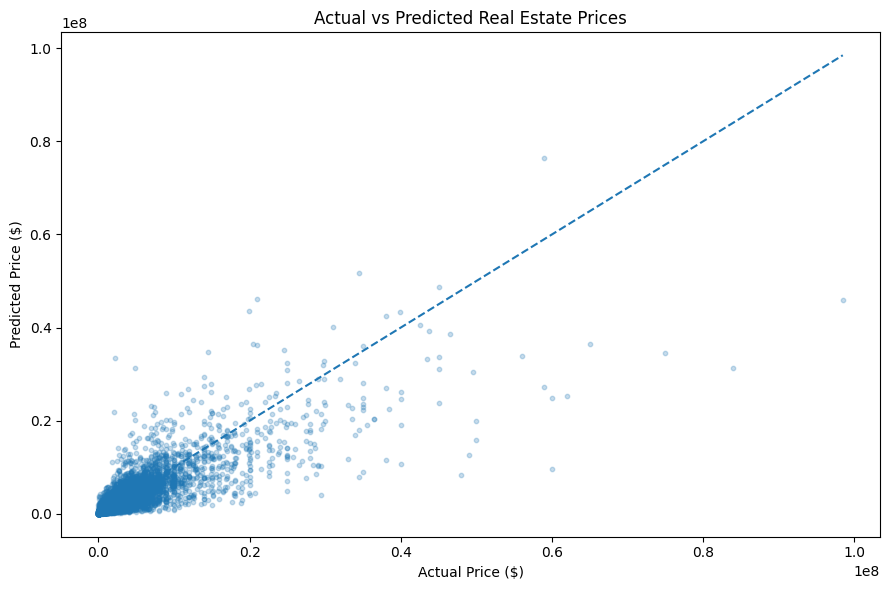

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    results_df["actual_price"],
    results_df["predicted_price"],
    alpha=0.25,
    s=10
)

max_price = max(
    results_df["actual_price"].max(),
    results_df["predicted_price"].max()
)

plt.plot(
    [0, max_price],
    [0, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Real Estate Prices")

plt.tight_layout()
plt.show()

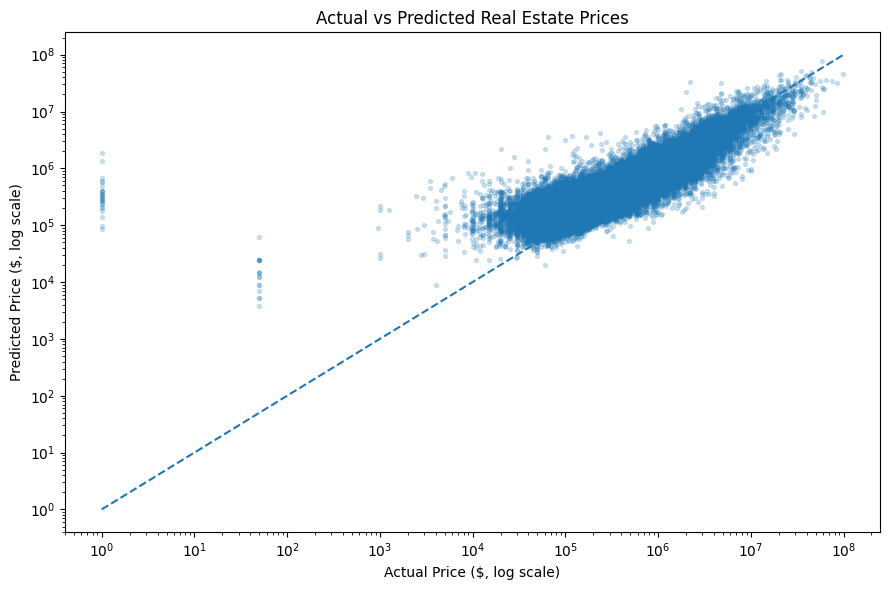

In [82]:
plt.figure(figsize=(9, 6))

plt.scatter(
    results_df["actual_price"],
    results_df["predicted_price"],
    alpha=0.20,
    s=8
)

min_price = min(
    results_df["actual_price"].min(),
    results_df["predicted_price"].min()
)

max_price = max(
    results_df["actual_price"].max(),
    results_df["predicted_price"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Actual Price ($, log scale)")
plt.ylabel("Predicted Price ($, log scale)")
plt.title("Actual vs Predicted Real Estate Prices")

plt.tight_layout()
plt.show()

In [83]:
price_bins = [
    0,
    100_000,
    250_000,
    500_000,
    1_000_000,
    5_000_000,
    float("inf")
]

price_labels = [
    "< $100K",
    "$100K–250K",
    "$250K–500K",
    "$500K–1M",
    "$1M–5M",
    "> $5M"
]

results_df["price_segment"] = pd.cut(
    results_df["actual_price"],
    bins=price_bins,
    labels=price_labels,
    right=False
)

segment_results = (
    results_df
    .groupby("price_segment", observed=True)
    .agg(
        properties=("actual_price", "size"),
        median_actual_price=("actual_price", "median"),
        MAE=("absolute_error", "mean"),
        median_percentage_error=("percentage_error", "median")
    )
    .reset_index()
)

segment_results

,price_segment,properties,median_actual_price,MAE,median_percentage_error
0,< $100K,10460,70000.0,1.116958e+05,135.731358
1,$100K–250K,39412,184760.0,7.648500e+04,26.867828
2,$250K–500K,69706,359900.0,8.074677e+04,15.630409
3,$500K–1M,42479,660000.0,1.574468e+05,16.620735
4,$1M–5M,17773,1575000.0,5.831816e+05,23.184757
5,> $5M,1653,7850000.0,4.082683e+06,31.626162


In [95]:
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

TRAINING_DATA_PATH = PROCESSED_DIR / "real_estate_clean.csv"

columns_to_save = [
    "price",
    "bed",
    "bath",
    "house_size",
    "acre_lot",
    "state",
    "city",
    "zip_code",
]

df_model[columns_to_save].to_csv(
    TRAINING_DATA_PATH,
    index=False
)

print("Дані збережено:", TRAINING_DATA_PATH)
print("Кількість рядків:", len(df_model))
print("Кількість колонок:", len(columns_to_save))

Дані збережено: ..\data\processed\real_estate_clean.csv
Кількість рядків: 907414
Кількість колонок: 8
